# 02 - Preprocessing (Cleaning)

In this notebook I:
1. Load the raw GB columns (`datasets/raw/gb_columns_raw.csv`, made by notebook 01)
2. Keep only the years 2015 to 2019
3. Find missing and wrong values
4. Fill them
5. Save the clean data in `datasets/processed`

### 1. Import libraries

In [1]:
import os

import pandas as pd
import matplotlib.pyplot as plt
import holidays

### 2. Load the raw data

`gb_columns_raw.csv` has the three original columns I need, exactly as in the OPSD files:
- `utc_timestamp`: time in UTC
- `GB_GBN_load_actual_entsoe_transparency`: electricity load of Great Britain (MW), from the time series file
- `GB_temperature`: temperature of Great Britain (°C), from the weather file

This file is in the GitHub repository, so the project can start from this notebook.

In [2]:
raw_folder = "../datasets/raw"
processed_folder = "../datasets/processed"
figures_folder = "../results/figures"

os.makedirs(processed_folder, exist_ok=True)
os.makedirs(figures_folder, exist_ok=True)

data = pd.read_csv(raw_folder + "/gb_columns_raw.csv")
data.columns = ["time", "load", "temperature"]

data.head()

,time,load,temperature
0,2014-12-31T23:00:00Z,NaN,6.425
1,2015-01-01T00:00:00Z,26758.0,6.565
2,2015-01-01T01:00:00Z,27166.0,6.715
3,2015-01-01T02:00:00Z,24472.0,6.893
4,2015-01-01T03:00:00Z,23003.0,7.093


In [3]:
data["time"] = pd.to_datetime(data["time"], utc=True)

# keep only 2015 to 2019 (2020 is removed because of COVID-19)
data = data[(data["time"] >= "2015-01-01") & (data["time"] < "2020-01-01")]
data = data.reset_index(drop=True)

print("Rows:", len(data))
data.head()

Rows: 43824


,time,load,temperature
0,2015-01-01 00:00:00+00:00,26758.0,6.565
1,2015-01-01 01:00:00+00:00,27166.0,6.715
2,2015-01-01 02:00:00+00:00,24472.0,6.893
3,2015-01-01 03:00:00+00:00,23003.0,7.093
4,2015-01-01 04:00:00+00:00,21832.0,7.297


In [4]:
# check that no hour is missing from the time column
expected_hours = pd.date_range("2015-01-01", "2019-12-31 23:00", freq="h", tz="UTC")
print("Expected hours:", len(expected_hours))
print("Hours in data :", len(data))

Expected hours: 43824
Hours in data : 43824


In [5]:
data.describe()

,load,temperature
count,43818.000000,43824.000000
mean,35523.255671,9.865687
std,7748.569922,5.508153
min,511.000000,-4.516000
25%,29544.000000,5.681000
50%,36145.000000,9.492500
75%,41154.000000,13.873000
max,57388.000000,29.105000


In [6]:
# keep a copy of the original load so I can compare before and after cleaning
data["load_original"] = data["load"]

### 3. Missing values

In [7]:
print(data.isnull().sum())

time             0
load             6
temperature      0
load_original    6
dtype: int64


In [8]:
data[data["load"].isnull()]

,time,load,temperature,load_original
2089,2015-03-29 01:00:00+00:00,NaN,7.372,NaN
2090,2015-03-29 02:00:00+00:00,NaN,7.299,NaN
2091,2015-03-29 03:00:00+00:00,NaN,7.115,NaN
19561,2017-03-26 01:00:00+00:00,NaN,3.303,NaN
19562,2017-03-26 02:00:00+00:00,NaN,3.095,NaN
19563,2017-03-26 03:00:00+00:00,NaN,2.894,NaN


6 hours of load are missing. They are all on the day the clocks change in March.

### 4. Wrong values

I use three simple rules.

**Rule 1: load below 10,000 MW.** GB demand never goes this low (normal range is about 15,000 to 57,000 MW), so these values are errors.

**Rule 2: one-hour spikes.** If the load jumps up or down by more than 5,000 MW for **one hour only** and then goes back, it is an error.
Real demand for a whole country cannot change like this. Example: 41,926 → 24,036 → 42,462 MW.

**Rule 3: blocks of too-low values.** Some errors last several hours, so rule 2 does not catch them. If the load is below 65% of the normal level for that hour, it is an error.
The normal level is the average of the same hour last week and the same hour next week. Bank holidays and Christmas to New Year are skipped, because demand really is low on those days.

In [9]:
# Rule 1
too_low = data["load"] < 10000
print("Rule 1 - values below 10,000 MW:", too_low.sum())

data[too_low][["time", "load"]]

Rule 1 - values below 10,000 MW: 24


,time,load
3878,2015-06-11 14:00:00+00:00,7982.0
6637,2015-10-04 13:00:00+00:00,5512.0
34653,2018-12-14 21:00:00+00:00,1957.0
34654,2018-12-14 22:00:00+00:00,1984.0
34655,2018-12-14 23:00:00+00:00,2010.0
34656,2018-12-15 00:00:00+00:00,2038.0
34657,2018-12-15 01:00:00+00:00,2082.0
34658,2018-12-15 02:00:00+00:00,2128.0
38423,2019-05-20 23:00:00+00:00,511.0
38424,2019-05-21 00:00:00+00:00,539.0


In [10]:
data.loc[too_low, "load"] = None

In [11]:
# Rule 2
previous_hour = data["load"].shift(1)
next_hour = data["load"].shift(-1)

change_from_previous = data["load"] - previous_hour
change_to_next = data["load"] - next_hour

# a spike goes far away from BOTH neighbours in the same direction
spike_up = (change_from_previous > 5000) & (change_to_next > 5000)
spike_down = (change_from_previous < -5000) & (change_to_next < -5000)
spikes = spike_up | spike_down

print("Rule 2 - one-hour spikes:", spikes.sum())

# show a few with the hour before and after
spike_table = pd.DataFrame({
    "time": data["time"],
    "hour before": previous_hour,
    "load": data["load"],
    "hour after": next_hour,
})
spike_table[spikes].head(10)

Rule 2 - one-hour spikes: 59


,time,hour before,load,hour after
3985,2015-06-16 01:00:00+00:00,26480.0,31874.0,24506.0
6514,2015-09-29 10:00:00+00:00,41926.0,24036.0,42462.0
6566,2015-10-01 14:00:00+00:00,41688.0,23858.0,42758.0
7744,2015-11-19 16:00:00+00:00,46501.0,27748.0,52043.0
12288,2016-05-27 00:00:00+00:00,28797.0,15056.0,26831.0
12402,2016-05-31 18:00:00+00:00,41854.0,32968.0,39544.0
30136,2018-06-09 16:00:00+00:00,32784.0,18699.0,33556.0
30593,2018-06-28 17:00:00+00:00,38373.0,20575.0,36105.0
30682,2018-07-02 10:00:00+00:00,37508.0,23936.0,38778.0
30782,2018-07-06 14:00:00+00:00,37962.0,22536.0,38478.0


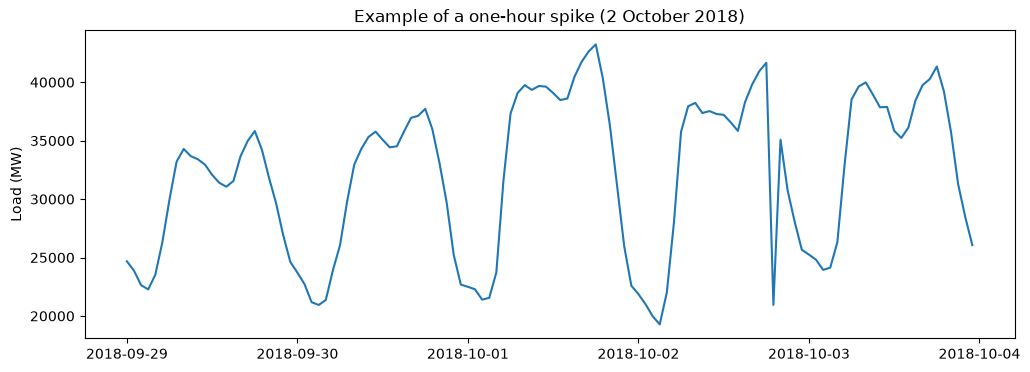

In [12]:
# example of one spike
example = data[(data["time"] >= "2018-09-29") & (data["time"] < "2018-10-04")]

plt.figure(figsize=(12, 4))
plt.plot(example["time"], example["load"])
plt.title("Example of a one-hour spike (2 October 2018)")
plt.ylabel("Load (MW)")
plt.savefig(figures_folder + "/02_spike_example.png")
plt.show()

In [13]:
data.loc[spikes, "load"] = None

In [14]:
# Rule 3
same_hour_last_week = data["load"].shift(168)
same_hour_next_week = data["load"].shift(-168)
normal_level = (same_hour_last_week + same_hour_next_week) / 2

too_low_block = data["load"] < 0.65 * normal_level

# skip bank holidays and Christmas to New Year, demand is really low there
uk_time = data["time"].dt.tz_convert("Europe/London")
uk_holidays = holidays.UK(subdiv="ENG", years=[2015, 2016, 2017, 2018, 2019])
is_holiday = uk_time.dt.date.isin(list(uk_holidays.keys()))
is_christmas = ((uk_time.dt.month == 12) & (uk_time.dt.day >= 24)) | ((uk_time.dt.month == 1) & (uk_time.dt.day <= 2))

too_low_block = too_low_block & ~is_holiday & ~is_christmas
print("Rule 3 - blocks of too-low values:", too_low_block.sum())

block_table = pd.DataFrame({
    "time": data["time"],
    "load": data["load"],
    "normal level": normal_level.round(),
})
block_table[too_low_block]

Rule 3 - blocks of too-low values: 26


,time,load,normal level
2819,2015-04-28 11:00:00+00:00,25594.0,42573.0
2820,2015-04-28 12:00:00+00:00,25090.0,42420.0
3879,2015-06-11 15:00:00+00:00,24813.0,41686.0
6636,2015-10-04 12:00:00+00:00,21755.0,36767.0
34659,2018-12-15 03:00:00+00:00,15184.0,24150.0
36903,2019-03-18 15:00:00+00:00,23142.0,42025.0
36904,2019-03-18 16:00:00+00:00,23947.0,43683.0
36952,2019-03-20 16:00:00+00:00,22516.0,43650.0
36953,2019-03-20 17:00:00+00:00,23187.0,44764.0
37228,2019-04-01 04:00:00+00:00,14609.0,25352.0


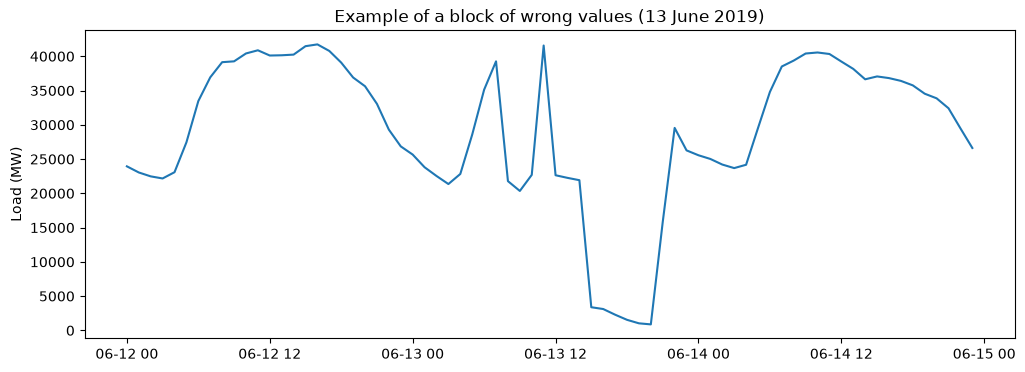

In [15]:
# example: 13 June 2019, original data
example = data[(data["time"] >= "2019-06-12") & (data["time"] < "2019-06-15")]

plt.figure(figsize=(12, 4))
plt.plot(example["time"], example["load_original"])
plt.title("Example of a block of wrong values (13 June 2019)")
plt.ylabel("Load (MW)")
plt.savefig(figures_folder + "/02_block_example.png")
plt.show()

On 13 June 2019 the load drops to about 22,000 MW from 08:00 to 14:00 (rule 3) and then to almost zero (rule 1), on a normal Thursday.

In [16]:
data.loc[too_low_block, "load"] = None

# mark every hour that will be filled (missing in the file + rule 1 + rule 2 + rule 3)
data["was_filled"] = data["load"].isnull().astype(int)

print("Hours to fill:", data["was_filled"].sum(), "out of", len(data))
print()
print("Hours to fill per year:")
print(data.groupby(data["time"].dt.year)["was_filled"].sum())

Hours to fill: 115 out of 43824

Hours to fill per year:
time
2015    13
2016     2
2017     3
2018    26
2019    71
Name: was_filled, dtype: int64


### 5. Fill the missing values

- Gaps of **3 hours or less**: linear interpolation (a straight line between the hour before and the hour after)
- Gaps **longer than 3 hours**: the value from the same hour one week earlier (168 hours before)

In [17]:
# find how long each gap is
is_missing = data["load"].isnull()

# give the same number to all hours that belong to the same gap
gap_number = (is_missing != is_missing.shift()).cumsum()
gap_length = is_missing.groupby(gap_number).transform("sum")

short_gap = is_missing & (gap_length <= 3)
long_gap = is_missing & (gap_length > 3)

print("Hours in short gaps:", short_gap.sum())
print("Hours in long gaps:", long_gap.sum())

Hours in short gaps: 80
Hours in long gaps: 35


In [18]:
# short gaps: linear interpolation
interpolated = data["load"].interpolate()
data.loc[short_gap, "load"] = interpolated[short_gap]

# long gaps: same hour last week
last_week = data["load"].shift(168)
data.loc[long_gap, "load"] = last_week[long_gap]

print("Missing values left:", data["load"].isnull().sum())

Missing values left: 0


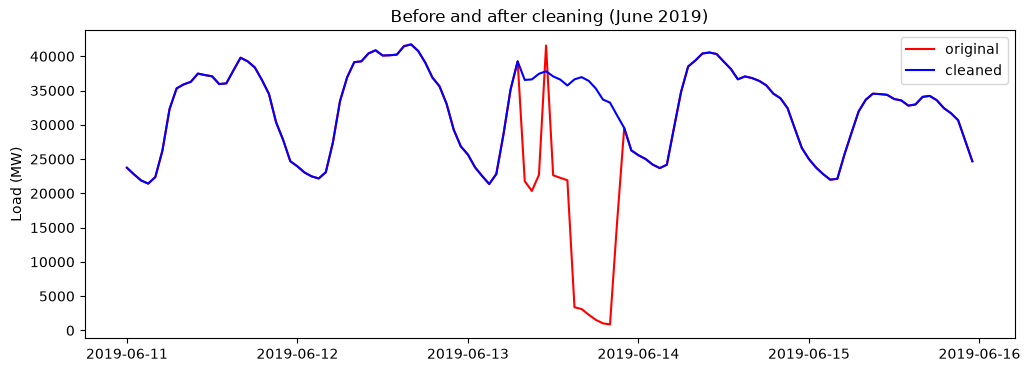

In [19]:
# before and after for the worst period (13 June 2019)
period = (data["time"] >= "2019-06-11") & (data["time"] < "2019-06-16")

plt.figure(figsize=(12, 4))
plt.plot(data[period]["time"], data[period]["load_original"], label="original", color="red")
plt.plot(data[period]["time"], data[period]["load"], label="cleaned", color="blue")
plt.title("Before and after cleaning (June 2019)")
plt.ylabel("Load (MW)")
plt.legend()
plt.savefig(figures_folder + "/02_cleaning_example.png")
plt.show()

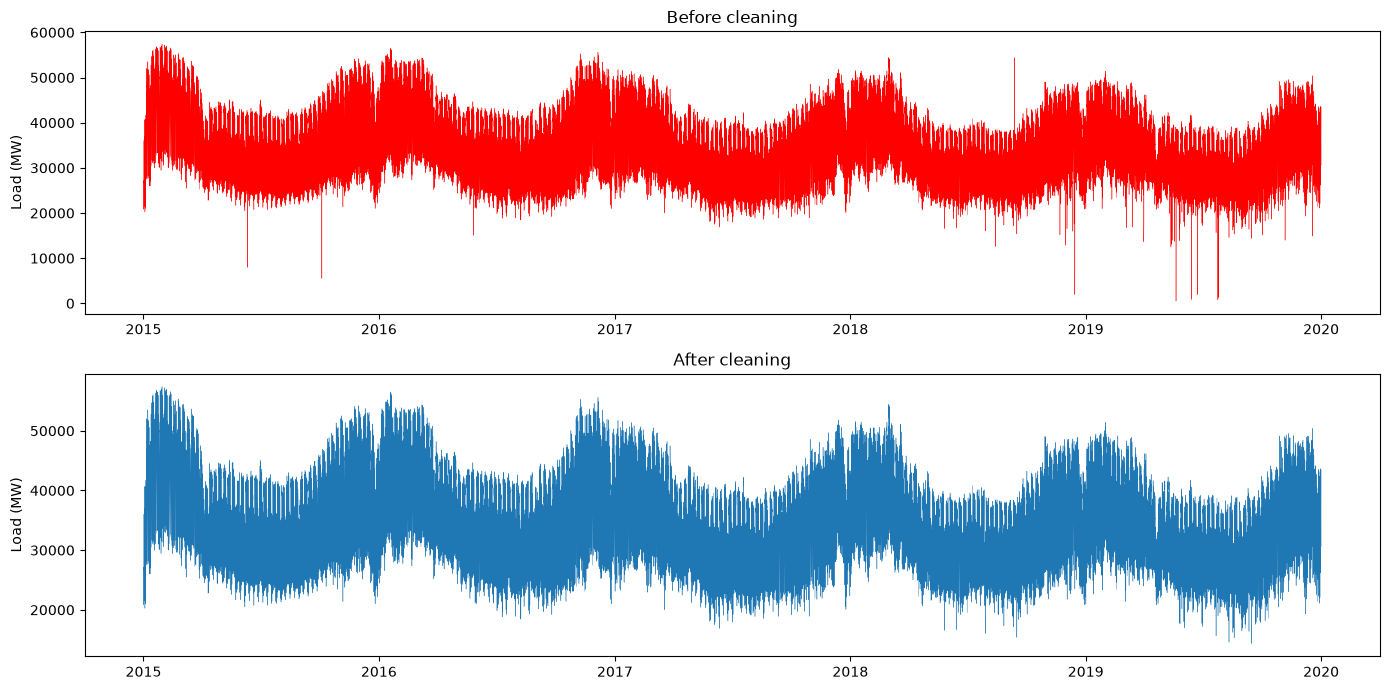

Lowest value now : 14356.0
Highest value now: 57388.0


In [20]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7))

axes[0].plot(data["time"], data["load_original"], linewidth=0.3, color="red")
axes[0].set_title("Before cleaning")
axes[0].set_ylabel("Load (MW)")

axes[1].plot(data["time"], data["load"], linewidth=0.3)
axes[1].set_title("After cleaning")
axes[1].set_ylabel("Load (MW)")

plt.tight_layout()
plt.savefig(figures_folder + "/02_before_after.png")
plt.show()

print("Lowest value now :", data["load"].min())
print("Highest value now:", data["load"].max())

### 6. Save the clean data

In [21]:
clean = data[["time", "load", "temperature", "was_filled"]]
clean.to_csv(processed_folder + "/gb_clean_2015_2019.csv", index=False)

print("Saved", len(clean), "rows")
clean.head()

Saved 43824 rows


,time,load,temperature,was_filled
0,2015-01-01 00:00:00+00:00,26758.0,6.565,0
1,2015-01-01 01:00:00+00:00,27166.0,6.715,0
2,2015-01-01 02:00:00+00:00,24472.0,6.893,0
3,2015-01-01 03:00:00+00:00,23003.0,7.093,0
4,2015-01-01 04:00:00+00:00,21832.0,7.297,0


### Summary

- Kept 2 columns: `GB_GBN_load_actual_entsoe_transparency` (as `load`) and `GB_temperature` (as `temperature`), 2015-2019
- 6 missing hours and wrong values (below 10,000 MW, one-hour spikes, blocks of too-low values) were found and filled
- Short gaps: linear interpolation. Long gaps: same hour last week
- Every filled hour is marked in the `was_filled` column

**Next:** notebook 03 - exploratory data analysis (EDA).